Tehtävä 12
Muodosta signaali

s(t)=4sin(6t)+3sin(15t)+5cos(20t)
näytteenottovälillä 0,1 s aikavälillä 0≤t<100 s.

a) Piirrä osasignaalit ja niiden summa. Rajaa aika-akselia tarvittaessa.

b) Laske summan Fourier-muunnos FFT-algoritmilla ja sen tehospektri.

c) Muodosta taajuusakseli hertseinä ja tunnista spektrin huiput.

d) Vertaa huippujen taajuuksia alkuperäisten funktioiden kulmataajuuksiin.

e) Palauta signaali käänteismuunnoksella ja vertaa sitä alkuperäiseen.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

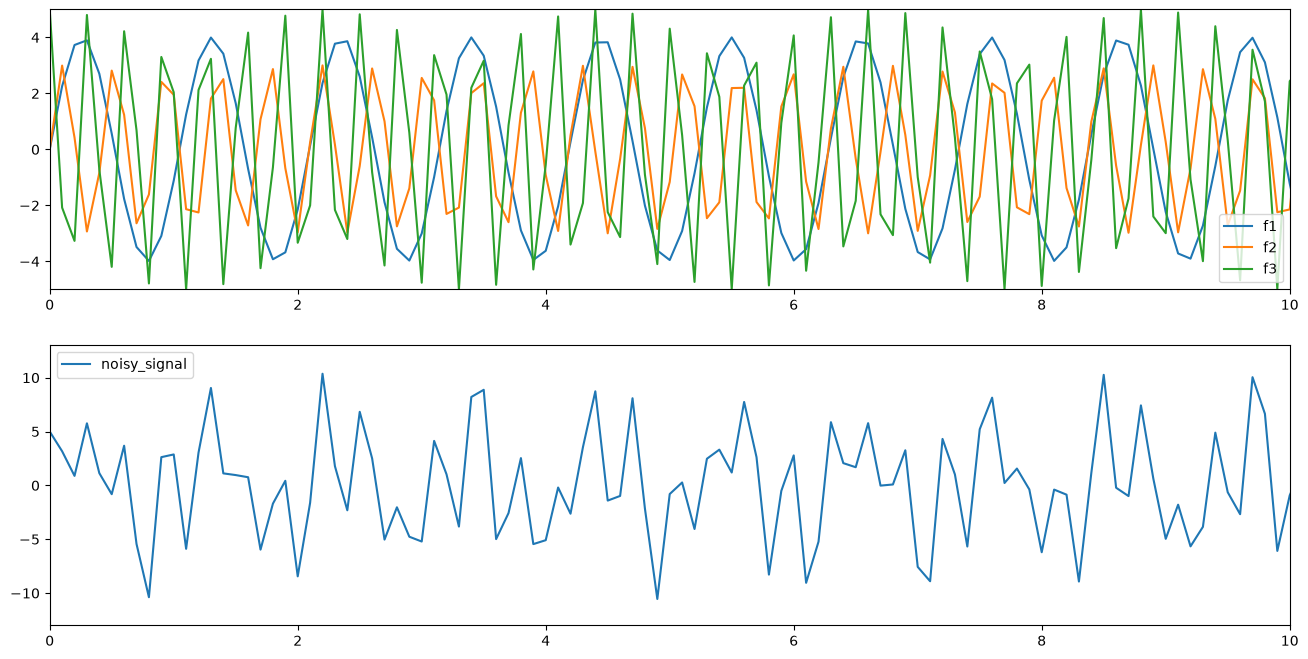

In [11]:
#a) Piirrä osasignaalit ja niiden summa. Rajaa aika-akselia tarvittaessa.

dt= 0.1
t = np.arange(0, 100, dt) 
f1 = 4*np.sin(6*t)
f2 = 3*np.sin(15*t)
f3 = 5*np.cos(20*t)
noisy_signal = f1 + f2 + f3

plt.figure(figsize=(16,8))
plt.subplot(2,1,1)
plt.axis([0,10,-5,5])
plt.plot(t, f1)
plt.plot(t, f2)
plt.plot(t, f3)
plt.legend(['f1', 'f2', 'f3'])
plt.subplot(2,1,2)
plt.plot(t, noisy_signal)
plt.axis([0,10,-13,13])
plt.legend([ 'noisy_signal'])



In [4]:
#b) Laske summan Fourier-muunnos FFT-algoritmilla ja sen tehospektri.'
f = noisy_signal
N = len(f)

#fourier
fourier = np.fft.fft(f, N)

#tehospektri
psd = fourier*np.conj(fourier)/N


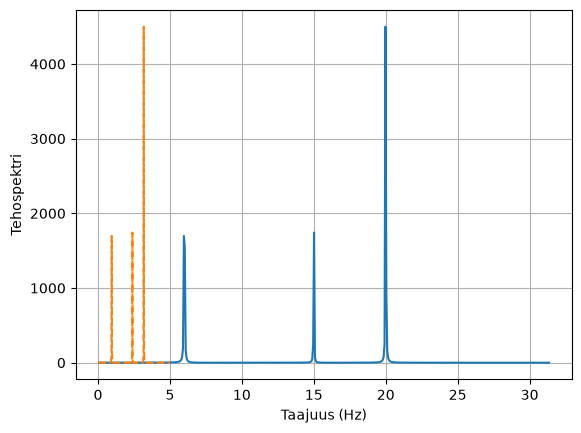

In [13]:
#c) Muodosta taajuusakseli hertseinä ja tunnista spektrin huiput.

#freq = 1/(dt*N)*np.arange(N) #Taajuudet
freq = np.fft.fftfreq(N,dt)
L = np.arange(1, np.floor(N/2), dtype='int') #Määritellään ne tehospektrin arvot, joita käytetään
PSD = np.array([freq[L], psd[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(2*np.pi*PSD[0,:], PSD[1,:])
plt.plot(PSD[0,:], PSD[1,:], "--")
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
plt.grid()
plt.show()

#spektrin huiput n. 0.9hz, 2.4hz ja 3.2hz  Kulmataajuudet havaitaan selvästi piikkeinä

In [14]:
#d) Vertaa huippujen taajuuksia alkuperäisten funktioiden kulmataajuuksiin.
# f1 = 4*np.sin(6*t)
# f2 = 3*np.sin(15*t)
# f3 = 5*np.cos(20*t)

wf1 = 6
wf2 = 15
wf3 = 20
#f = w/(2pi)
ff1 = wf1/(2*np.pi)
ff2 = wf2/(2*np.pi)
ff3 = wf3/(2*np.pi)

taajuudet = PSD[0, :]
tehot = PSD[1, :]

print(ff1, ff2, ff3) #alkuperäisten funktioiden taajuudet

0.954929658551372 2.3873241463784303 3.183098861837907


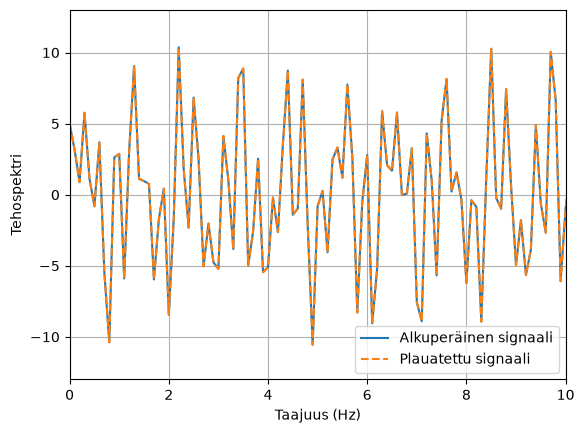

In [16]:
#e) Palauta signaali käänteismuunnoksella ja vertaa sitä alkuperäiseen.
signal = np.fft.ifft(fourier, N).real

plt.plot(t, f, label="Alkuperäinen signaali")
plt.plot(t, signal, "--", label="Plauatettu signaali")
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
plt.legend()
plt.axis([0,10,-13,13])
plt.grid()
plt.show()